# Import & Setup

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTE
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import roc_curve, precision_recall_curve, auc, f1_score, precision_score, recall_score


# Load data

In [ ]:
#Original Data
data = pd.read_csv("diabetes.csv")

data

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [ ]:
# Shape & Head
print("Shape:", data.shape)

data.head()

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:
#Info
data.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
# Describe
data.describe()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [12]:
# Check for missing values
print(data.isnull().sum())


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


# EDA

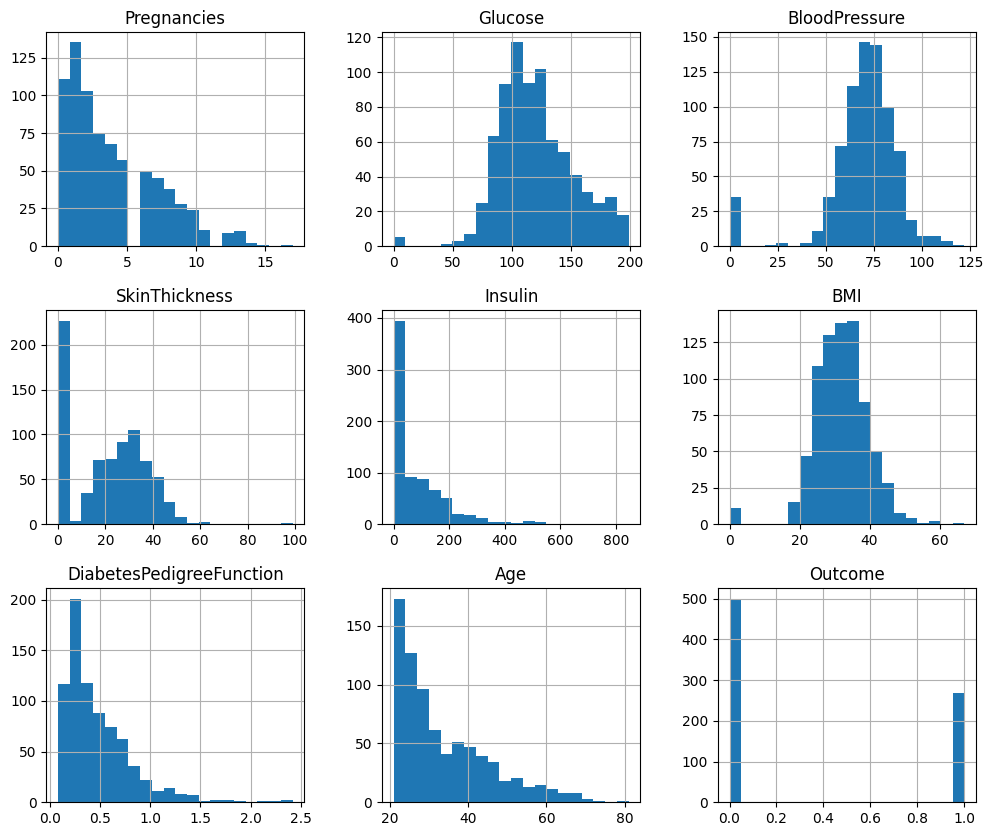

In [15]:
# 3. Plot histograms for all features
data.hist(bins=20, figsize=(12,10))
plt.show()

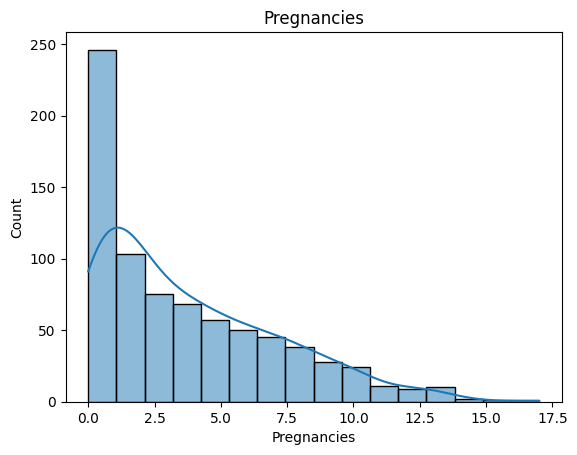

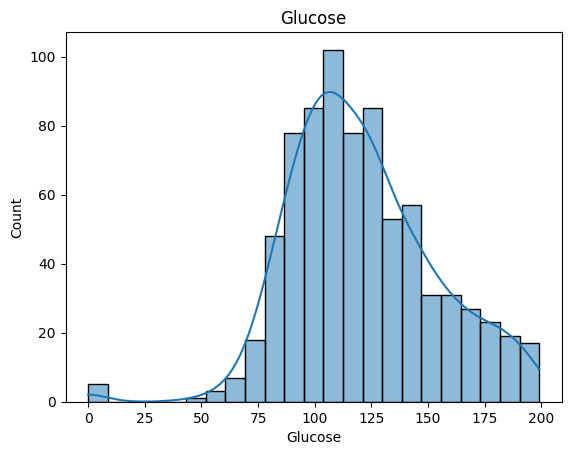

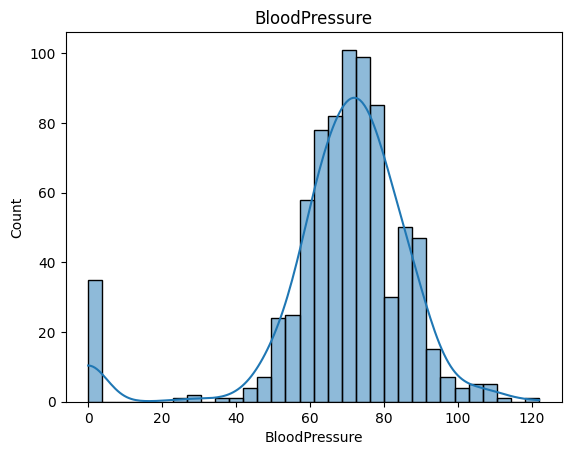

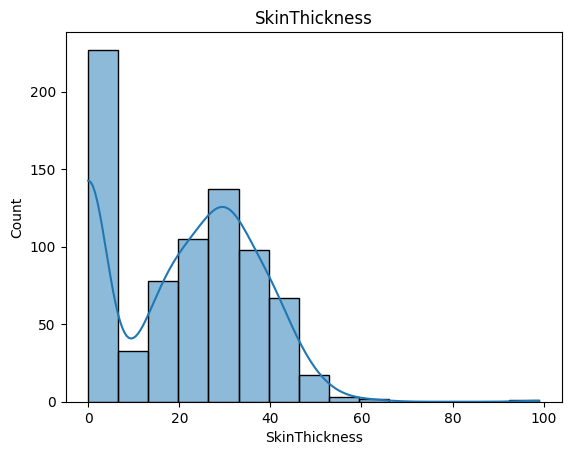

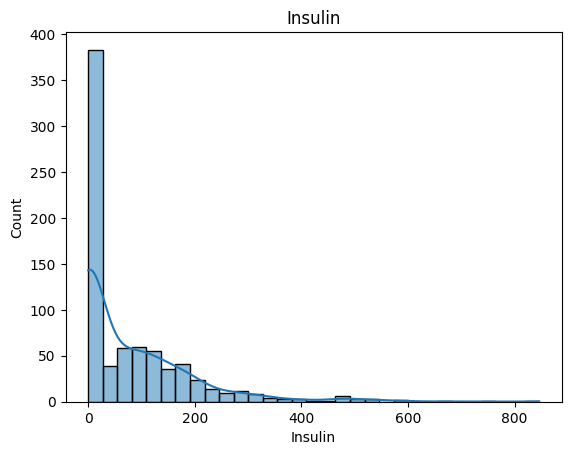

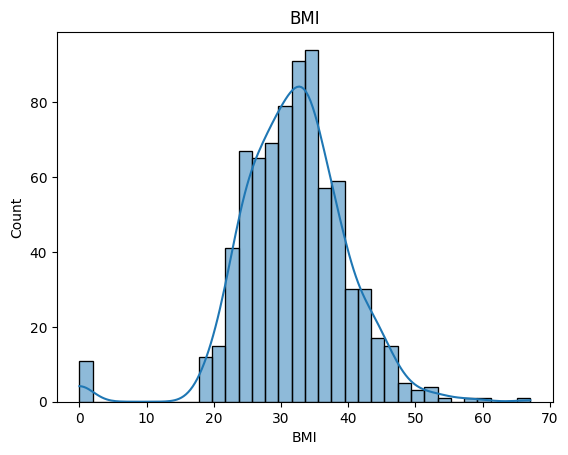

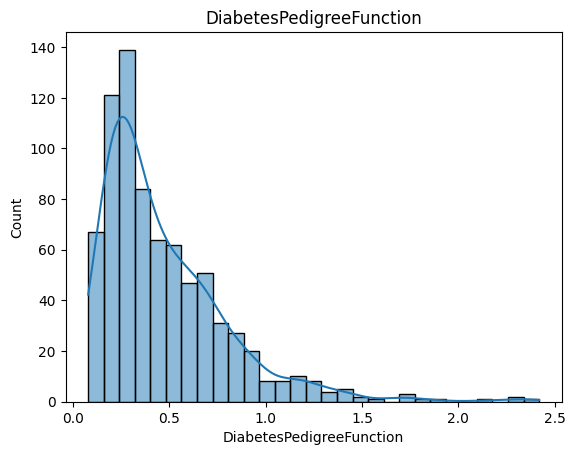

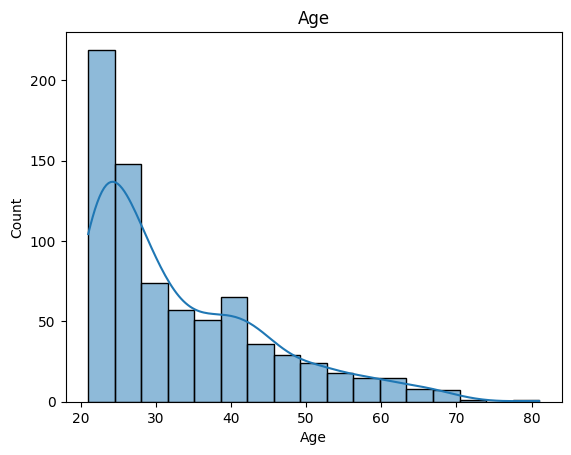

In [16]:
# 4. Plot distribution for each feature (with KDE curve)
for col in data.columns[:-1]:  # exclude Outcome
    sns.histplot(data[col], kde=True)
    plt.title(col)
    plt.show()

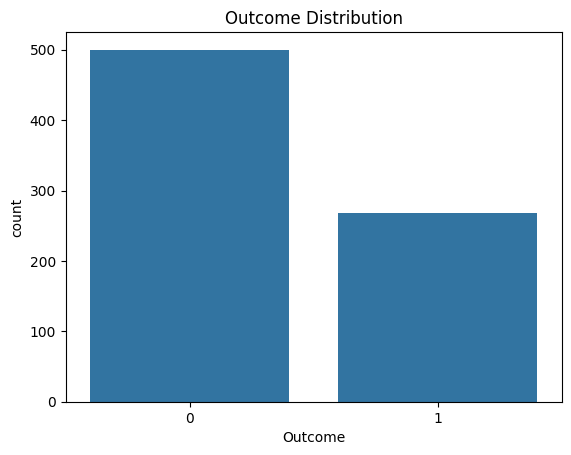

In [17]:
# 5. Check class balance for Outcome
sns.countplot(x='Outcome', data=data)
plt.title("Outcome Distribution")
plt.show()

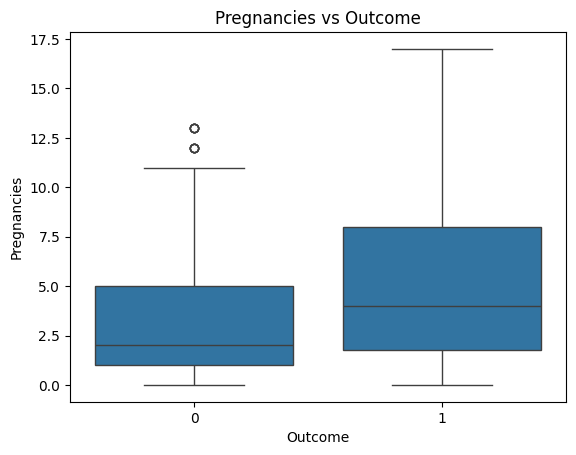

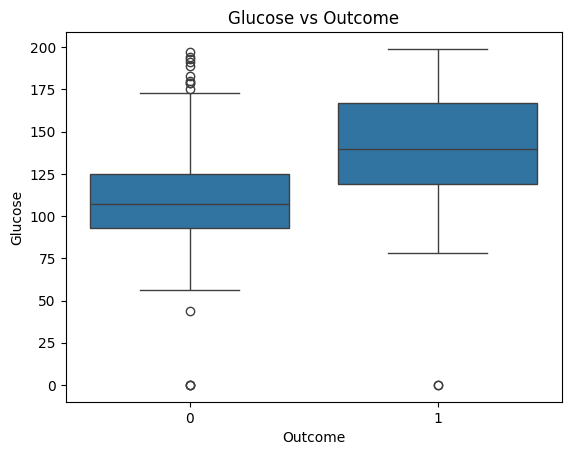

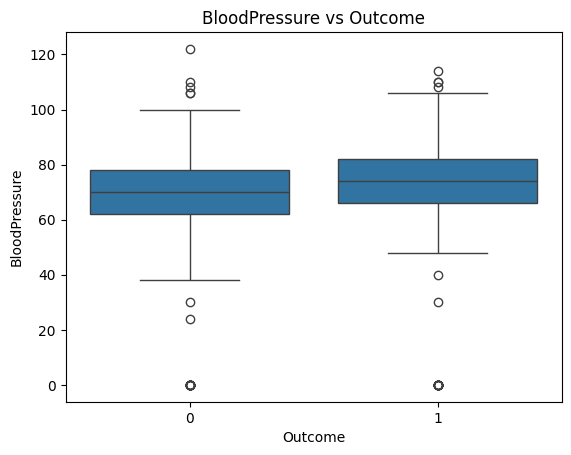

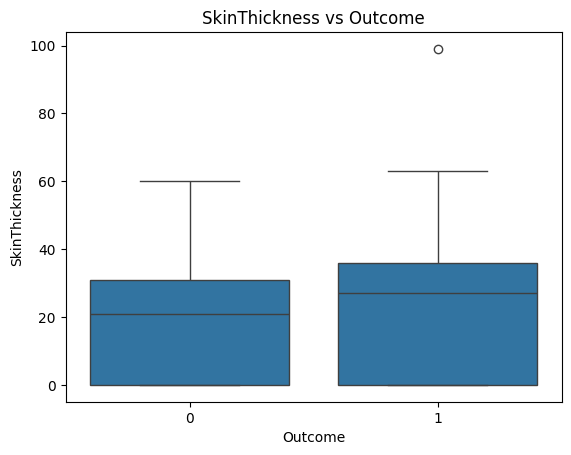

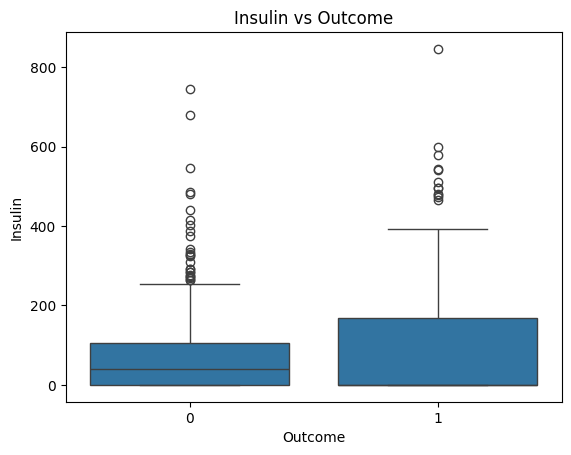

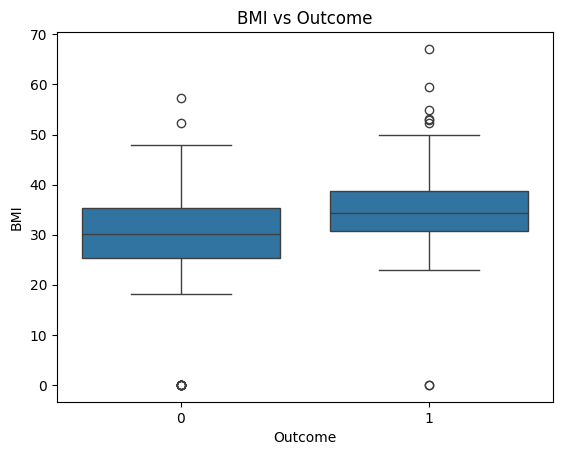

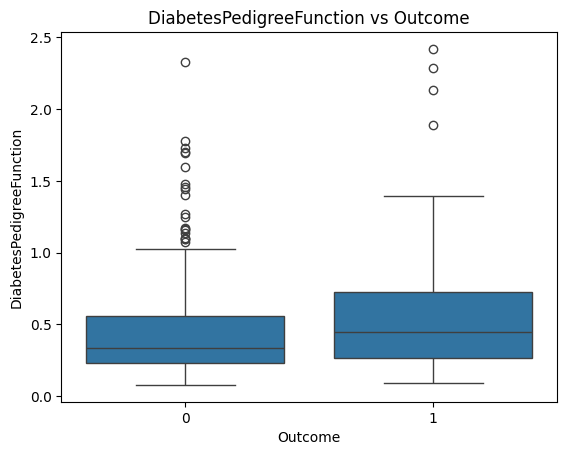

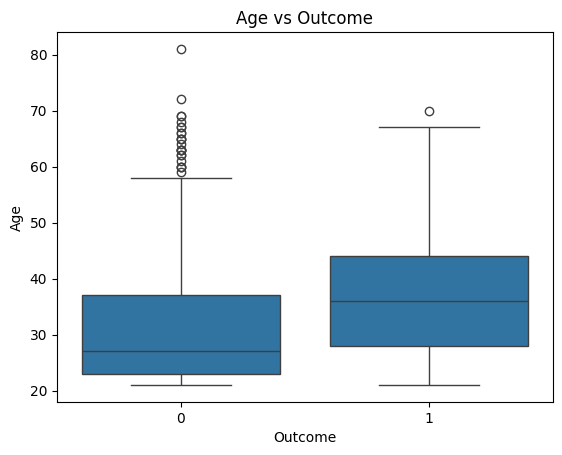

In [18]:
# 6. Boxplots for each feature vs Outcome (to detect outliers and separation)
for col in data.columns[:-1]:
    sns.boxplot(x='Outcome', y=col, data=data)
    plt.title(f"{col} vs Outcome")
    plt.show()

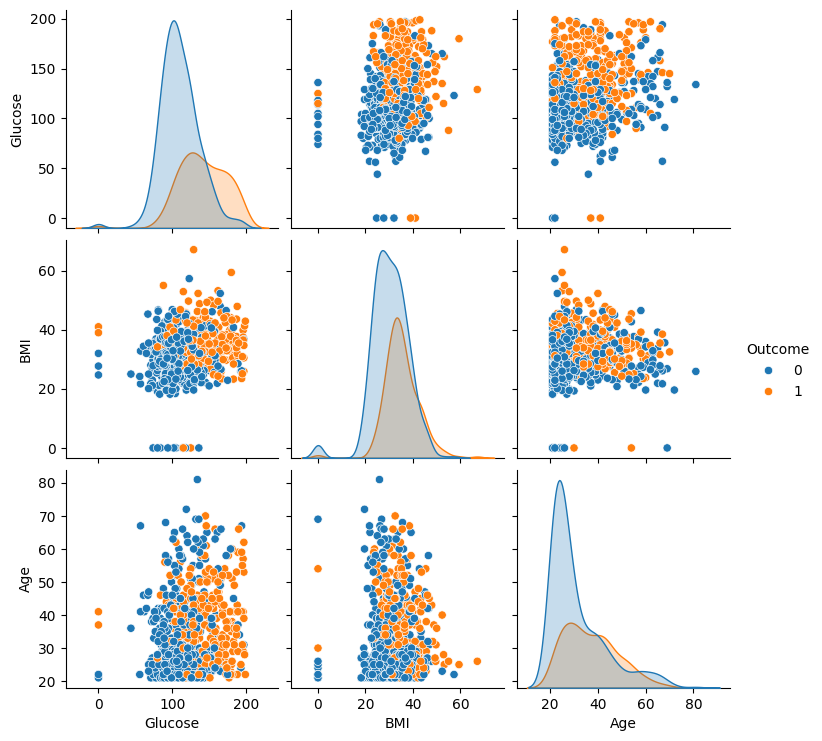

In [19]:
# 8. Pairplot for selected features
sns.pairplot(data[["Glucose", "BMI", "Age", "Outcome"]], hue="Outcome")
plt.show()


C:\Users\e\AppData\Local\Temp\ipykernel_6900\442300029.py:4: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data[data["Outcome"]==0][col], label="Non-Diabetic", shade=True)
C:\Users\e\AppData\Local\Temp\ipykernel_6900\442300029.py:5: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data[data["Outcome"]==1][col], label="Diabetic", shade=True)


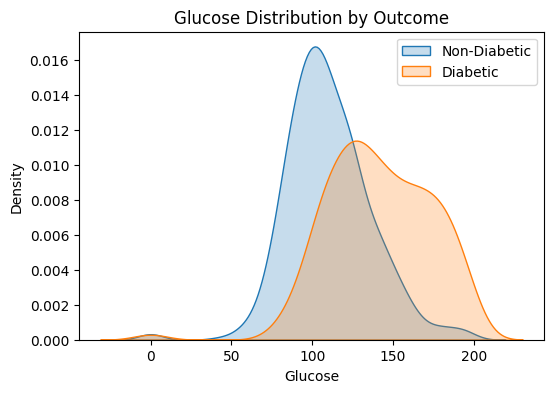

C:\Users\e\AppData\Local\Temp\ipykernel_6900\442300029.py:4: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data[data["Outcome"]==0][col], label="Non-Diabetic", shade=True)
C:\Users\e\AppData\Local\Temp\ipykernel_6900\442300029.py:5: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data[data["Outcome"]==1][col], label="Diabetic", shade=True)


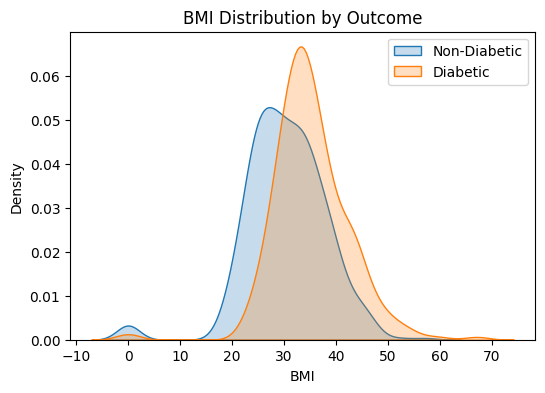

C:\Users\e\AppData\Local\Temp\ipykernel_6900\442300029.py:4: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data[data["Outcome"]==0][col], label="Non-Diabetic", shade=True)
C:\Users\e\AppData\Local\Temp\ipykernel_6900\442300029.py:5: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data[data["Outcome"]==1][col], label="Diabetic", shade=True)


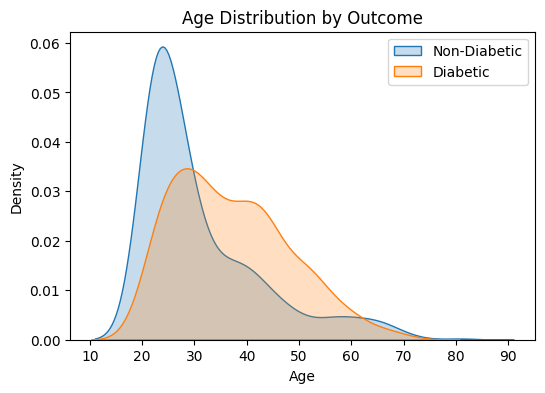

In [20]:
# 9. KDE plots comparing distributions for diabetics vs non-diabetics
for col in ["Glucose", "BMI", "Age"]:
    plt.figure(figsize=(6,4))
    sns.kdeplot(data[data["Outcome"]==0][col], label="Non-Diabetic", shade=True)
    sns.kdeplot(data[data["Outcome"]==1][col], label="Diabetic", shade=True)
    plt.title(f"{col} Distribution by Outcome")
    plt.legend()
    plt.show()


In [21]:
# 10. Grouped mean values for diabetics vs non-diabetics
print(data.groupby("Outcome").mean())


         Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
Outcome                                                                      
0           3.298000  109.980000      68.184000      19.664000   68.792000   
1           4.865672  141.257463      70.824627      22.164179  100.335821   

               BMI  DiabetesPedigreeFunction        Age  
Outcome                                                  
0        30.304200                  0.429734  31.190000  
1        35.142537                  0.550500  37.067164  


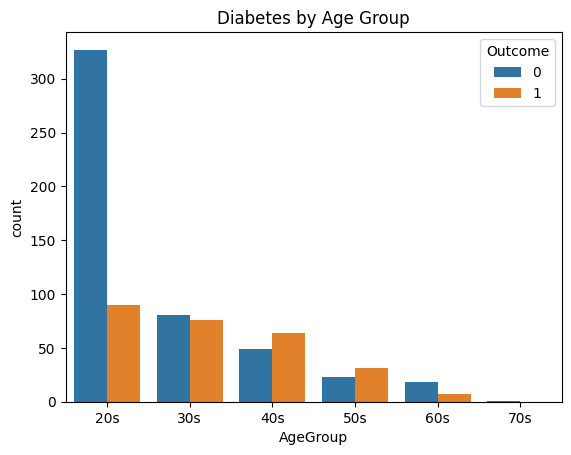

In [22]:
# 11. Age bins analysis
data["AgeGroup"] = pd.cut(data["Age"], bins=[20,30,40,50,60,70,80], labels=["20s","30s","40s","50s","60s","70s"])
sns.countplot(x="AgeGroup", hue="Outcome", data=data)
plt.title("Diabetes by Age Group")
plt.show()


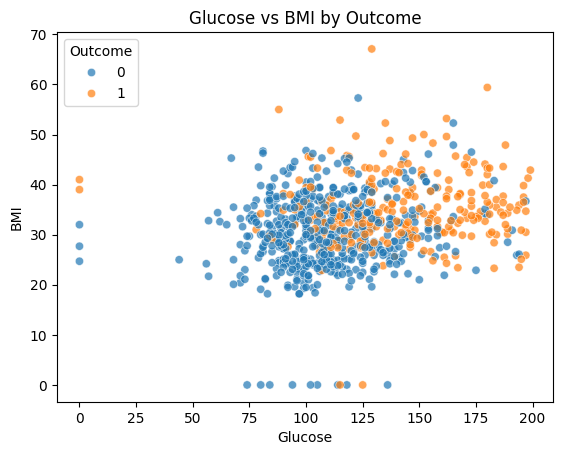

In [23]:
# 12. Scatterplot Glucose vs BMI
sns.scatterplot(x="Glucose", y="BMI", hue="Outcome", data=data, alpha=0.7)
plt.title("Glucose vs BMI by Outcome")
plt.show()


Numeric columns used for correlation:
 ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


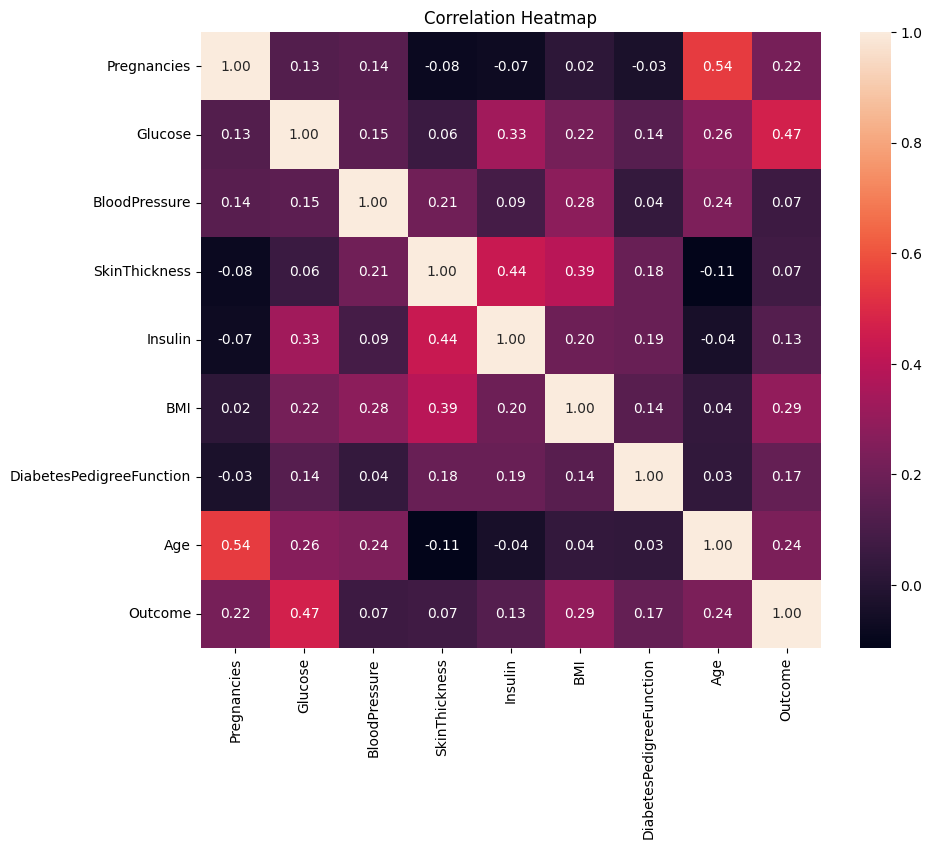

In [30]:
# 7. Correlation heatmap (using numeric data only)
numeric_data = data.select_dtypes(include=[np.number])   # selects numeric columns only
print("Numeric columns used for correlation:\n", numeric_data.columns.tolist())


plt.figure(figsize=(10,8))
sns.heatmap(numeric_data.corr(), annot=True, cmap="rocket", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()  

# Phase 2: Data Preparation


In [51]:
# 1. Handle invalid values (replace zeros with NaN)
cols_with_zero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
data[cols_with_zero] = data[cols_with_zero].replace(0, np.nan)

# Fill missing values with median
data[cols_with_zero] = data[cols_with_zero].fillna(data[cols_with_zero].median())

print("DONE")

DONE


C:\Users\e\AppData\Local\Temp\ipykernel_6900\3274137958.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[cols_with_zero] = data[cols_with_zero].replace(0, np.nan)
C:\Users\e\AppData\Local\Temp\ipykernel_6900\3274137958.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[cols_with_zero] = data[cols_with_zero].fillna(data[cols_with_zero].median())


In [ ]:
# 2. Feature Engineering (Example: Age Group + BMI Category)
data['AgeGroup'] = pd.cut(
    data['Age'],
    bins=[20, 30, 40, 50, 60, 100],
    labels=['20s', '30s', '40s', '50s', '60+'])

data['BMICategory'] = pd.cut(
    data['BMI'],
    bins=[0, 18.5, 24.9, 29.9, 100],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese'])

data["Glucose_BMI"] = data["Glucose"] * data["BMI"]
data["Age_DPF"] = data["Age"] * data["DiabetesPedigreeFunction"]
data["PregnantBinary"] = data["Pregnancies"].apply(lambda x: 1 if x > 0 else 0)



print('DONE')

DONE


C:\Users\e\AppData\Local\Temp\ipykernel_6900\2469361986.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['AgeGroup'] = pd.cut(
C:\Users\e\AppData\Local\Temp\ipykernel_6900\2469361986.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['BMICategory'] = pd.cut(
C:\Users\e\AppData\Local\Temp\ipykernel_6900\2469361986.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the docu

In [53]:
# 3. Remove Outliers using IQR (only numeric columns)
numeric_cols = data.select_dtypes(include=[np.number]).columns

Q1 = data[numeric_cols].quantile(0.25)
Q3 = data[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

data = data[~((data[numeric_cols] < (Q1 - 1.5 * IQR)) | 
              (data[numeric_cols] > (Q3 + 1.5 * IQR))).any(axis=1)]

print('DONE')

DONE


In [ ]:
# 4. Prepare Features and Target
X = data.drop("Outcome", axis=1)
y = data["Outcome"]

# One-hot encode categorical features (AgeGroup, BMICategory)
X = pd.get_dummies(X, drop_first=True)


print("DONE")

DONE


In [55]:
# 4. Feature Selection (Top K features)
selector = SelectKBest(score_func=f_classif, k=8)  # choose top 8 features
X_selected = selector.fit_transform(X, y)

selected_features = X.columns[selector.get_support()]
print("Selected Features:", selected_features.tolist())

Selected Features: ['Glucose', 'BMI', 'Age', 'Glucose_BMI', 'Age_DPF', 'AgeGroup_40s', 'BMICategory_Normal', 'BMICategory_Obese']


c:\Users\e\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [ 3  4 10] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
c:\Users\e\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


In [56]:
# 5. Handle Imbalance (SMOTE)
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_selected, y)

print("Before SMOTE:", y.value_counts().to_dict())
print("After SMOTE:", pd.Series(y_resampled).value_counts().to_dict())

Before SMOTE: {0: 105, 1: 55}
After SMOTE: {0: 105, 1: 105}


In [57]:
# 6. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_resampled, y_resampled, test_size=0.2, random_state=42, stratify=y_resampled)

print('DONE')

DONE


In [80]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_train, y_train)


In [60]:
# 6. Standardize numerical features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Final Train shape:", X_train.shape)
print("Final Test shape:", X_test.shape)


print("DONE")

Final Train shape: (168, 8)
Final Test shape: (42, 8)
DONE


In [62]:
# 7. Check Class Balance
print("Class distribution:\n", y.value_counts(normalize=True))

Class distribution:
 Outcome
0    0.65625
1    0.34375
Name: proportion, dtype: float64


# Model Building & Competition

In [72]:
# Logistic Regression
# -----------------------
log_reg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
log_reg.fit(X_train, y_train)

y_pred_lr = log_reg.predict(X_test)
y_prob_lr = log_reg.predict_proba(X_test)[:, 1]

print(" Logistic Regression ")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("ROC AUC:", roc_auc_score(y_test, y_prob_lr))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))
print("Classification Report:\n", classification_report(y_test, y_pred_lr))
print("\n")

 Logistic Regression 
Accuracy: 0.7857142857142857
ROC AUC: 0.8571428571428572
Confusion Matrix:
 [[18  3]
 [ 6 15]]
Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.86      0.80        21
           1       0.83      0.71      0.77        21

    accuracy                           0.79        42
   macro avg       0.79      0.79      0.78        42
weighted avg       0.79      0.79      0.78        42





In [74]:

# Define the parameter grid
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': [0.001, 0.01, 0.1, 1],
    'kernel': ['rbf']
}

# Initialize SVM
svm = SVC(probability=True, random_state=42)

# GridSearchCV
grid = GridSearchCV(svm, param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

# Best model
svm_best = grid.best_estimator_

# Predictions
y_pred = svm_best.predict(X_test)
y_pred_proba = svm_best.predict_proba(X_test)[:, 1]

# Evaluation
print("Best Params:", grid.best_params_)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_pred_proba))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Best Params: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
Accuracy: 0.8333333333333334
ROC AUC: 0.8639455782312925

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.86      0.84        21
           1       0.85      0.81      0.83        21

    accuracy                           0.83        42
   macro avg       0.83      0.83      0.83        42
weighted avg       0.83      0.83      0.83        42



In [94]:
# Random Forest
# -----------------------
rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print("===== Random Forest =====")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("ROC AUC:", roc_auc_score(y_test, y_prob_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("Classification Report:\n", classification_report(y_test, y_pred_rf))
print("\n")

===== Random Forest =====
Accuracy: 0.7857142857142857
ROC AUC: 0.929705215419501
Confusion Matrix:
 [[17  4]
 [ 5 16]]
Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.81      0.79        21
           1       0.80      0.76      0.78        21

    accuracy                           0.79        42
   macro avg       0.79      0.79      0.79        42
weighted avg       0.79      0.79      0.79        42





Fitting 3 folds for each of 30 candidates, totalling 90 fits


c:\Users\e\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:183: UserWarning: [01:06:27] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best Params: {'subsample': 0.8, 'n_estimators': np.int64(200), 'max_depth': np.int64(3), 'learning_rate': 0.01, 'gamma': 0, 'colsample_bytree': 0.6}
===== XGBoost (Tuned + SMOTE) =====
Accuracy: 0.8333333333333334
ROC AUC: 0.9274376417233561
Confusion Matrix:
 [[17  4]
 [ 3 18]]
Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.81      0.83        21
           1       0.82      0.86      0.84        21

    accuracy                           0.83        42
   macro avg       0.83      0.83      0.83        42
weighted avg       0.83      0.83      0.83        42



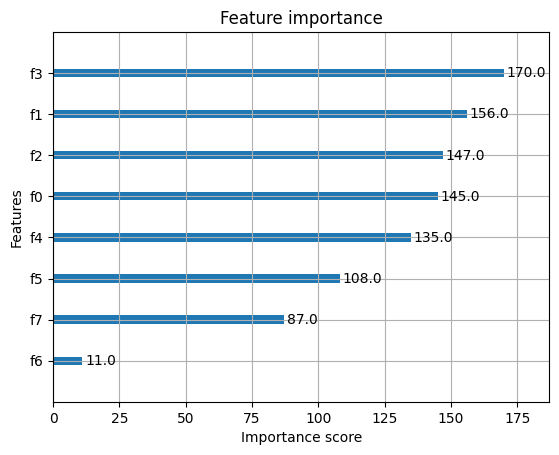

In [81]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
from xgboost import XGBClassifier
import numpy as np
import matplotlib.pyplot as plt
from xgboost import plot_importance

# ========================
# Step 1: Balance Data with SMOTE
# ========================
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_train, y_train)

# ========================
# Step 2: Define Parameter Grid
# ========================
param_dist = {
    'n_estimators': np.arange(100, 800, 100),
    'max_depth': np.arange(3, 15, 2),
    'learning_rate': [0.001, 0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'gamma': [0, 0.1, 0.2, 0.3]
}

xgb = XGBClassifier(
    use_label_encoder=False,
    eval_metric="logloss",
    random_state=42
)

# ========================
# Step 3: RandomizedSearchCV
# ========================
random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist,
    n_iter=30,
    scoring='roc_auc',
    cv=3,
    n_jobs=-1,
    verbose=1,
    random_state=42
)

random_search.fit(X_res, y_res)

best_xgb = random_search.best_estimator_
print("Best Params:", random_search.best_params_)

# ========================
# Step 4: Evaluate on Test Data
# ========================
y_pred_xgb = best_xgb.predict(X_test)
y_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]

print("===== XGBoost (Tuned + SMOTE) =====")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("ROC AUC:", roc_auc_score(y_test, y_prob_xgb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))
print("Classification Report:\n", classification_report(y_test, y_pred_xgb))

# ========================
# Step 5: Feature Importance (Visualization)
# ========================
plot_importance(best_xgb)
plt.show()


In [82]:
import os

# Create folder for plots
os.makedirs("plots", exist_ok=True)

In [84]:
# Dictionary of models
models = {
    "Logistic Regression": log_reg,
    "SVM": svm_best,
    "Random Forest": rf,
    "XGBoost": best_xgb}

In [87]:
# 1. Cross-Validation Reports
# ------------------------------
def cross_val_metrics(model, X, y, cv=5):
    skf = StratifiedKFold(n_splits=cv, shuffle=True, random_state=42)
    acc = cross_val_score(model, X, y, cv=skf, scoring='accuracy')
    roc = cross_val_score(model, X, y, cv=skf, scoring='roc_auc')
    return acc.mean(), roc.mean()

cv_results = {}
for name, model in models.items():
    acc, roc = cross_val_metrics(model, X_train, y_train)
    cv_results[name] = {"CV_Accuracy": acc, "CV_ROC_AUC": roc}

cv_df = pd.DataFrame(cv_results).T
print("Cross Validation Results:\n", cv_df)

cv_df.to_csv("plots/CrossValidationResults.csv", index=True)

c:\Users\e\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:183: UserWarning: [01:20:21] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\e\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:183: UserWarning: [01:20:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\e\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:183: UserWarning: [01:20:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\e\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:183: UserWarning: [01:20:22] WARNING: C:\actions-runner\_work\

Cross Validation Results:
                      CV_Accuracy  CV_ROC_AUC
Logistic Regression     0.643316    0.754022
SVM                     0.768271    0.825087
Random Forest           0.726916    0.826990
XGBoost                 0.714973    0.806791


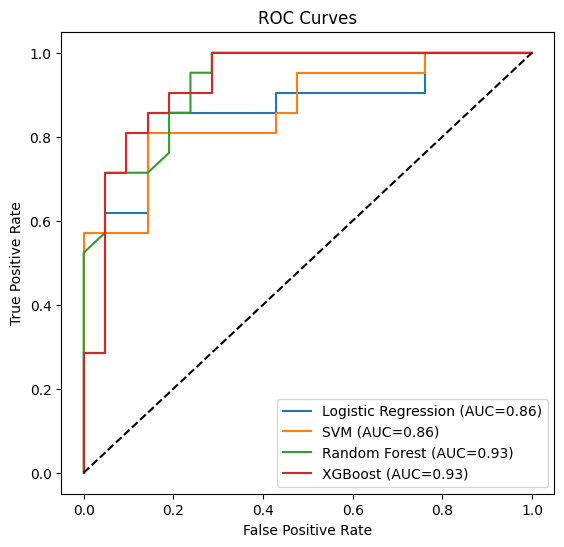

In [88]:
# 2. ROC & Precision-Recall Curves
# ------------------------------
plt.figure(figsize=(14,6))

# ROC Curve
plt.subplot(1,2,1)
for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:,1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr,tpr):.2f})")
plt.plot([0,1], [0,1], 'k--')
plt.title("ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

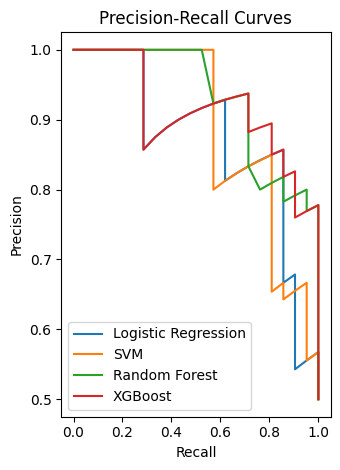

In [89]:
# Precision-Recall Curve
plt.subplot(1,2,2)
for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:,1]
    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    plt.plot(rec, prec, label=name)
plt.title("Precision-Recall Curves")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()

plt.tight_layout()
plt.savefig("plots/ROC_PR_Curves.png", dpi=300)
plt.show()

In [90]:
# 3. Stacking Classifier
# ------------------------------
stack = StackingClassifier(
    estimators=[
        ('lr', log_reg),
        ('rf', rf),
        ('xgb', best_xgb)
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
    n_jobs=-1)

stack.fit(X_train, y_train)
y_pred_stack = stack.predict(X_test)
y_prob_stack = stack.predict_proba(X_test)[:,1]

print("===== Stacking Classifier =====")
print("Accuracy:", accuracy_score(y_test, y_pred_stack))
print("ROC AUC:", roc_auc_score(y_test, y_prob_stack))
print("Classification Report:\n", classification_report(y_test, y_pred_stack))

# Add Stacking to models
models["Stacking"] = stack


===== Stacking Classifier =====
Accuracy: 0.9047619047619048
ROC AUC: 0.9501133786848073
Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.95      0.91        21
           1       0.95      0.86      0.90        21

    accuracy                           0.90        42
   macro avg       0.91      0.90      0.90        42
weighted avg       0.91      0.90      0.90        42



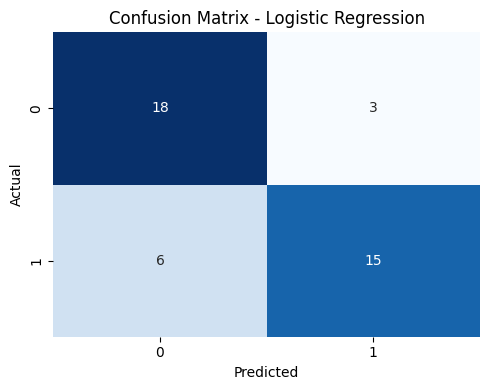

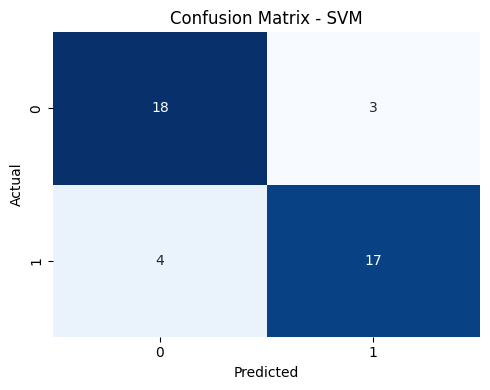

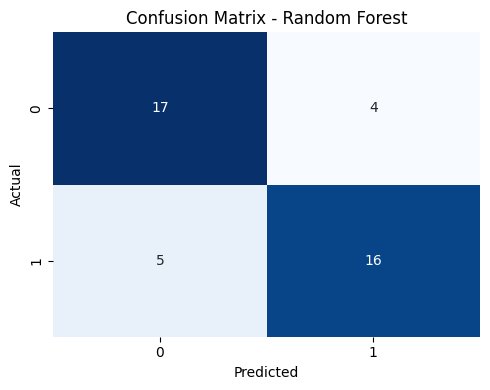

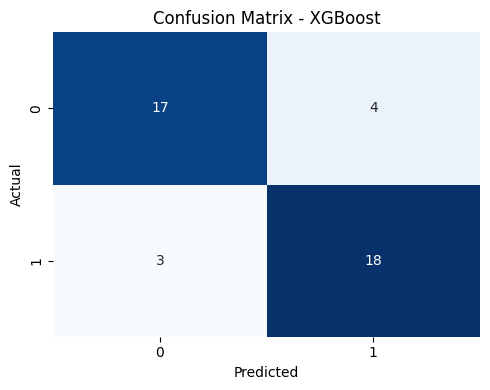

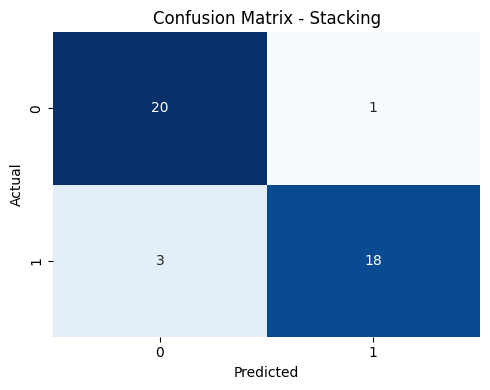

In [96]:
# 4. Confusion Matrix Visualization
# ------------------------------
def plot_conf_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f"Confusion Matrix - {title}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(f"plots/ConfusionMatrix_{title}.png", dpi=300)
    plt.show()

for name, model in models.items():
    y_pred = model.predict(X_test)
    plot_conf_matrix(y_test, y_pred, name)

In [92]:
# 5. Classification Report Table
# ------------------------------
report_data = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:,1]

    acc = accuracy_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_prob)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    report_data.append([name, acc, roc, prec, rec, f1])

report_df = pd.DataFrame(report_data, columns=["Model", "Accuracy", "ROC_AUC", "Precision", "Recall", "F1"])
print("\nComparison Table:\n")
print(report_df)

report_df.to_csv("plots/ModelComparison.csv", index=False)    


Comparison Table:

                 Model  Accuracy   ROC_AUC  Precision    Recall        F1
0  Logistic Regression  0.785714  0.857143   0.833333  0.714286  0.769231
1                  SVM  0.833333  0.863946   0.850000  0.809524  0.829268
2        Random Forest  0.785714  0.929705   0.800000  0.761905  0.780488
3              XGBoost  0.833333  0.927438   0.818182  0.857143  0.837209
4             Stacking  0.904762  0.950113   0.947368  0.857143  0.900000


In [106]:
def predict_diabetes_fixed(input_data, model, scaler, selected_features):
    """
    Predict if a patient is Diabetic or Non-Diabetic
    input_data: dict with patient features (Pregnancies, Glucose, etc.)
    model: trained model (Stacking or others)
    scaler: StandardScaler trained on selected features (8 features)
    selected_features: list of features used by the model (after SelectKBest)
    """
    df = pd.DataFrame([input_data])
    
    # التعامل مع صفر/missing
    cols_with_zero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
    df[cols_with_zero] = df[cols_with_zero].replace(0, np.nan)
    df[cols_with_zero] = df[cols_with_zero].fillna(data[cols_with_zero].median())
    
    # Feature Engineering (لازم يكون نفس اللي اتعمل في training)
    df['AgeGroup'] = pd.cut(df['Age'], bins=[20,30,40,50,60,100], labels=['20s','30s','40s','50s','60+'])
    df['BMICategory'] = pd.cut(df['BMI'], bins=[0,18.5,24.9,29.9,100], labels=['Underweight','Normal','Overweight','Obese'])
    df["Glucose_BMI"] = df["Glucose"] * df["BMI"]
    df["Age_DPF"] = df["Age"] * df["DiabetesPedigreeFunction"]
    df["PregnantBinary"] = df["Pregnancies"].apply(lambda x: 1 if x>0 else 0)
    
    # One-hot encoding
    df = pd.get_dummies(df, drop_first=True)
    
    # Add missing columns from training set (dummy variables)
    for col in selected_features:
        if col not in df.columns:
            df[col] = 0
    
    # Arrange columns in same order as selected_features
    df = df[selected_features]
    
    # Scale the selected features (already 8 features)
    df_scaled = scaler.transform(df)
    
    # Prediction
    pred = model.predict(df_scaled)[0]
    prob = model.predict_proba(df_scaled)[0][1]
    
    return {"prediction": "Diabetic" if pred==1 else "Non-Diabetic", "probability": prob}


In [110]:
# بيانات مريض جديد
new_patient = {
    "Pregnancies": 2,
    "Glucose": 130,
    "BloodPressure": 70,
    "SkinThickness": 20,
    "Insulin": 79,
    "BMI": 28.0,
    "DiabetesPedigreeFunction": 0.5,
    "Age": 35
}

# اختيار أفضل موديل، مثلاً Stacking
best_model = models["Stacking"]

# استدعاء الدالة
result = predict_diabetes_fixed(new_patient, best_model, scaler, selected_features)
print(result)


{'prediction': 'Diabetic', 'probability': np.float64(0.7275142312468281)}


c:\Users\e\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [112]:
joblib.dump(best_model, "best_model_stack.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(selected_features.tolist(), "selected_features.pkl")
joblib.dump(log_reg, "log_reg.pkl")
joblib.dump(svm_best, "svm_best.pkl")
joblib.dump(rf, "rf.pkl")
joblib.dump(best_xgb, "xgb.pkl")



['xgb.pkl']